In [17]:
import time
import matplotlib.pyplot as plt
from IPython.display import display

import threading

from src.monitor import run_monitor

from src.send import send_request

import pandas as pd
import matplotlib.pyplot as plt

# Testing sending one request

In [21]:
def generate_body(prompt):
    return {
        "messages": [{"role": "user", "content": prompt}],
        "max_tokens": 1024,
        "stream": True,
        "temperature": 0,
        "seed": 42,
        "ignore_eos": True,
        "cache_prompt": False,
        "chat_template_kwargs": {"enable_thinking": False},   # try to turn thinking off
    }

In [22]:
r = send_request(generate_body("Say hi"))
print(r["status"], "ttft:", r["ttft"], "ttft_content:", r["ttft_content"],
      "chunks:", r["chunks"])
print("ANSWER:", r["response_text"][:200])
print("THINKING:", r["reasoning_text"][:200])

ok ttft: 0.26413822174072266 ttft_content: 0.26413893699645996 chunks: 352
ANSWER: Hello! How can I help you today? 😊 What's on your mind? 🌟✨🚀🌍🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱
THINKING: 


# Test monitoring one request

In [23]:
prompt = "Find the three most-starred Python repos for web scraping, compare their licenses, and recommend one for a commercial project."

In [24]:
# Setup Monitoring
monitored_samples = []
stop_event = threading.Event()
monitor_thread = threading.Thread(target=run_monitor, args=(stop_event, monitored_samples), daemon=True)

# Start Monitoring
monitor_thread.start()           
time.sleep(1)

request_results = {}
try:
    # POST Request
    request_results = send_request(generate_body(prompt))
finally:
    time.sleep(1)
    stop_event.set() # kill monitoring
    monitor_thread.join()
    print(request_results['status'])

ok


# Test monitoring Multiple request

In [26]:
import time
import threading
from concurrent.futures import ThreadPoolExecutor

from src.send import run_workload    

# ---- Config ----
N = 50
CONCURRENCY = 10

# ---- Setup Monitoring ----
monitored_samples = []
stop_event = threading.Event()
monitor_thread = threading.Thread(
    target=run_monitor, args=(stop_event, monitored_samples), daemon=True
)

# ---- Start Monitoring ----
monitor_thread.start()
time.sleep(5)  # baseline samples before load

request_results = []
t0 = time.time()
try:
    request_results = run_workload([generate_body("Say hi")]*N, concurrency=CONCURRENCY)
finally:
    wall = time.time() - t0
    time.sleep(5)  # trailing samples after load
    stop_event.set()
    monitor_thread.join()

# ---- Summary ----
ok = [r for r in request_results if r.get("status") in (200, "ok")]
lat = sorted(r["latency"] for r in request_results)
print(f"{len(ok)}/{len(request_results)} succeeded in {wall:.1f}s "
      f"(concurrency={CONCURRENCY})")
if lat:
    print(f"latency  p50={lat[len(lat)//2]:.2f}s  max={lat[-1]:.2f}s")

50/50 succeeded in 69.0s (concurrency=10)
latency  p50=12.74s  max=16.13s


# Process Results

### Monitoring Results

In [27]:
df = pd.DataFrame(monitored_samples)

# elapsed seconds since first sample
df["t_elapsed"] = df["t_mono"] - df["t_mono"].iloc[0]

# bytes -> GB|
for c in ["rss", "uss", "vms", "sys_avail", "swap_used"]:
    df[c + "_gb"] = df[c] / 1024**3

df

,t_wall,t_mono,rss,uss,vms,sys_avail,swap_used,cpu_pct,t_elapsed,rss_gb,uss_gb,vms_gb,sys_avail_gb,swap_used_gb
0,1.792905e+09,33117.904301,1640435712,1637457920,77243994112,10493362176,0,0.0,0.000000,1.527775,1.525002,71.939075,9.772705,0.0
1,1.792905e+09,33118.114699,1640435712,1637457920,77243994112,10493345792,0,0.0,0.210397,1.527775,1.525002,71.939075,9.772690,0.0
2,1.792905e+09,33118.327682,1640435712,1637457920,77243994112,10492686336,0,0.0,0.423380,1.527775,1.525002,71.939075,9.772076,0.0
3,1.792905e+09,33118.536981,1640435712,1637457920,77243994112,10492837888,0,0.0,0.632680,1.527775,1.525002,71.939075,9.772217,0.0
4,1.792905e+09,33118.745364,1640435712,1637457920,77243994112,10493599744,0,0.0,0.841062,1.527775,1.525002,71.939075,9.772926,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
341,1.792906e+09,33190.179139,1874219008,1871241216,77476356096,10266304512,0,0.0,72.274837,1.745502,1.742729,72.155479,9.561241,0.0
342,1.792906e+09,33190.389087,1874219008,1871241216,77476356096,10266304512,0,0.0,72.484786,1.745502,1.742729,72.155479,9.561241,0.0
343,1.792906e+09,33190.598457,1874219008,1871241216,77476356096,10266304512,0,0.0,72.694155,1.745502,1.742729,72.155479,9.561241,0.0
344,1.792906e+09,33190.807475,1874219008,1871241216,77476356096,10266304512,0,0.0,72.903174,1.745502,1.742729,72.155479,9.561241,0.0


### Request Reponse

In [28]:
request_results

[{'idx': 0,
  'start': 1792905441.3257837,
  'end': 1792905457.2121952,
  'latency': 15.886411428451538,
  'prompt': 'Say hi',
  'response_text': "Hello! How can I help you today? 😊 What's on your mind? 🌟📚🚀🎨📱🧠🤖🎮🎵🎧📖📚🎧🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵🎧📚🎮🎵",
  'reasoning_text': '',
  't_start': 1792905441.325785,
  'ttft': 0.5503818988800049,
  'ttft_content': 0.5503826141357422,
  'total': 15.886314868927002,
  'chunks': 351,
  'status': 'ok'},
 {'idx': 1,
  'start': 1792905441.3268468,
  'end': 1792905457.2133338,
  'latency': 15.886487007141113,
  'prompt': 'Say hi',
  'response_text': "Hello! How can I help you today? 😊 What's on your mind? 🌟✨🚀🌍🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱

# Plot Monitoring Results

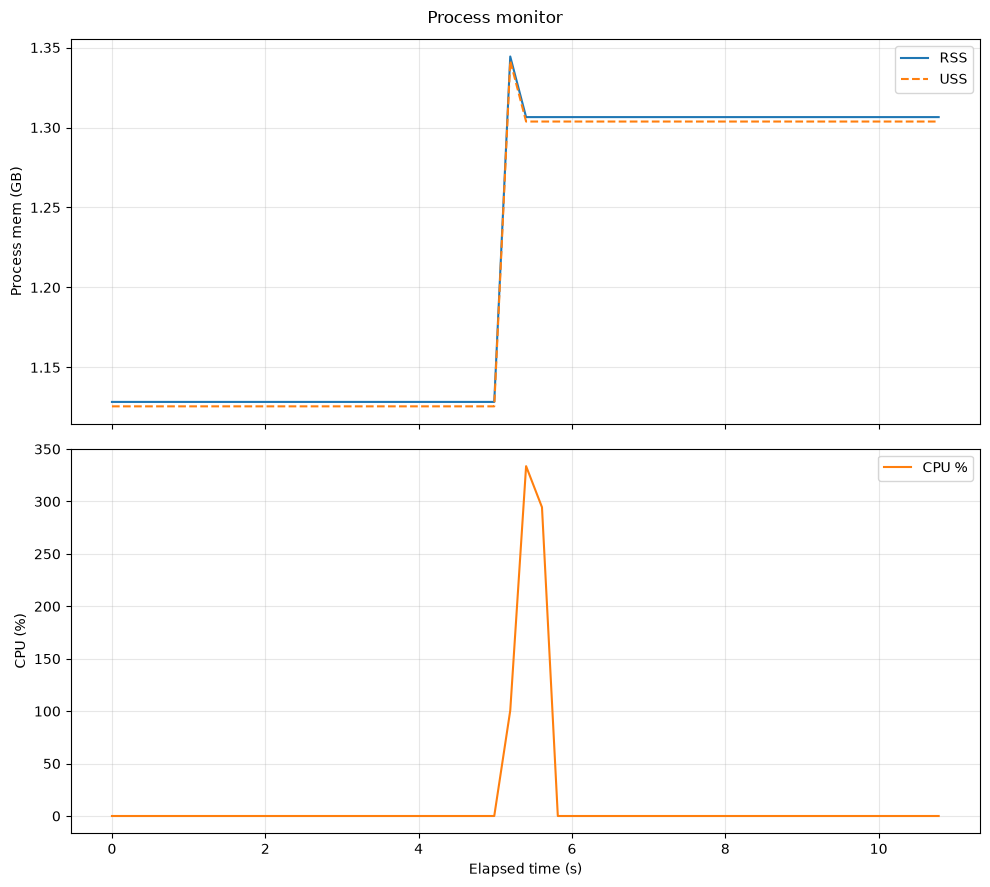

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9), sharex=True)

# 1. Process memory (rss/uss)
axes[0].plot(df["t_elapsed"], df["rss_gb"], label="RSS")
axes[0].plot(df["t_elapsed"], df["uss_gb"], label="USS", linestyle="--")
axes[0].set_ylabel("Process mem (GB)")
axes[0].legend()

# # 2. VMS (separate because it's much larger)
# axes[1].plot(df["t_elapsed"], df["vms_gb"], color="tab:purple", label="VMS")
# axes[1].set_ylabel("VMS (GB)")
# axes[1].legend()

# # 3. System available memory + swap
# axes[2].plot(df["t_elapsed"], df["sys_avail_gb"], color="tab:green", label="Sys available")
# axes[2].plot(df["t_elapsed"], df["swap_used_gb"], color="tab:red", label="Swap used")
# axes[2].set_ylabel("System (GB)")
# axes[2].legend()

# 4. CPU
axes[1].plot(df["t_elapsed"], df["cpu_pct"], color="tab:orange", label="CPU %")
axes[1].set_ylabel("CPU (%)")
axes[1].set_xlabel("Elapsed time (s)")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)

fig.suptitle("Process monitor")
fig.tight_layout()
plt.show()